<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM3510-BDA1/main/opim3510_banner.svg" width="100%" alt="OPIM 3510 banner"/>

<a href="https://colab.research.google.com/github/drdave-teaching/OPIM3510-BDA1/blob/main/M2_Forecasting/Week08_ExponentialSmoothing/1_CT_Exponential_Smoothing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exponential Smoothing and Holt-Winters 📉
-----------------------------------------
**Dr. Dave Wanik - University of Connecticut**

# 🔴 Where we left off
Last week's leaderboard on the 2021 test year:

| Model | MAPE | Skill vs. naive |
|---|---|---|
| Weekday-adjusted naive | 5.2% | +14% |
| Naive (yesterday) | 6.2% | 0% |
| Moving averages (3 and 7 days) | about 8% | about −30% |

Moving averages lost because they give **equal weight** to every day in the window - last Tuesday counts just as much as yesterday. This week's models fix that.

## By the end of this notebook, you will be able to:
* Explain **simple exponential smoothing** and what the smoothing parameter **alpha** controls
* Code it from scratch with a `for` loop, and check that **alpha = 1 is the naive forecast**
* Choose alpha with a **grid search on the training years only**
* Fit **Holt-Winters** (level + seasonality) with `statsmodels`
* Explain why the best model depends on the **forecast horizon** (tomorrow vs. next week)

# 🔴 Read the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [2]:
DATA_URL = "https://raw.githubusercontent.com/drdave-teaching/OPIM3510-BDA1/main/data/ct_daily_demand_2011_2021.csv"
daily = pd.read_csv(DATA_URL, index_col='Datetime', parse_dates=True)

# tell pandas these are evenly spaced days (statsmodels likes to know)
daily = daily.asfreq('D')
daily.head()

,Demand_GWh,Temp_avg,Temp_max
Datetime,,,
2011-01-01,77.071,39.90125,50.00
2011-01-02,77.400,42.08750,48.02
2011-01-03,90.982,29.12000,33.98
2011-01-04,93.627,27.98750,39.02
2011-01-05,93.066,27.92000,37.04


Our scorecard, same as always (**error = predicted − actual**):

In [3]:
def evaluate(actual, predicted, naive=None):
    """Score a forecast. Returns a pandas Series you can stack into a leaderboard.

    actual    : the true values (Series, list, or numpy array)
    predicted : your forecast for the same time steps
    naive     : (optional) a baseline forecast for the same time steps.
                If you give one, you also get "skill vs naive (%)":
                how much smaller your MAE is than the baseline's MAE.
                Positive = you beat the baseline. Negative = the baseline wins.

    Rows where any of the forecasts is missing (NaN) are dropped first,
    so every model is scored on exactly the same time steps.
    """
    # put everything side by side so the rows line up
    scores = pd.DataFrame({"actual": actual, "predicted": predicted})
    if naive is not None:
        scores["naive"] = naive

    # only score time steps where we have every number
    scores = scores.dropna()

    # error = predicted - actual
    error = scores["predicted"] - scores["actual"]

    # the four forecast KPIs
    bias = error.mean()
    mae = error.abs().mean()
    rmse = np.sqrt((error ** 2).mean())
    mape = (error.abs() / scores["actual"].abs()).mean() * 100

    results = {
        "n": len(scores),
        "bias": bias,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
    }

    # how much better than the baseline?
    if naive is not None:
        naive_error = scores["naive"] - scores["actual"]
        naive_mae = naive_error.abs().mean()
        results["skill vs naive (%)"] = (1 - mae / naive_mae) * 100

    return pd.Series(results).round(2)

In [4]:
# the two forecasts to beat, from last week
daily['Naive'] = daily['Demand_GWh'].shift(1)

train = daily.loc['2011':'2020']
weekday_avg = train['Demand_GWh'].groupby(train.index.dayofweek).mean()

daily['weekday'] = daily.index.dayofweek
daily['adjustment'] = daily['weekday'].map(weekday_avg) - daily['weekday'].shift(1).map(weekday_avg)
daily['Naive_weekday'] = daily['Naive'] + daily['adjustment']

# 🔴 Simple exponential smoothing
The idea: **each new forecast = a little bit of what just happened + a lot of what we already believed.**

$$f_t = \alpha \, d_{t-1} + (1 - \alpha) \, f_{t-1}$$

* $d_{t-1}$ is yesterday's actual demand (what just happened)
* $f_{t-1}$ is yesterday's forecast (what we already believed)
* $\alpha$ (alpha, between 0 and 1) is how much we **learn** from the newest day

| alpha | Behavior |
|---|---|
| close to 0 | stubborn: barely reacts to new data, very smooth |
| close to 1 | jumpy: chases every new data point |
| exactly 1 | forecast = yesterday's demand. **That's the naive forecast!** |

Why "exponential"? Plug the formula into itself and the weights on older days shrink by a factor of $(1 - \alpha)$ each step back: yesterday gets $\alpha$, the day before gets $\alpha(1-\alpha)$, then $\alpha(1-\alpha)^2$... Recent days count most, and nothing is ever completely forgotten.

## Build it from scratch

In [5]:
def simple_exp_smooth(demand, alpha):
    # demand: a pandas Series of actual values
    # returns a Series of 1-step-ahead forecasts (same index)
    d = demand.values
    f = np.full(len(d), np.nan)   # start with all forecasts missing

    # initialize: the first forecast we can make (for day 1) is day 0's demand
    f[1] = d[0]

    # every later forecast = alpha * (yesterday's actual) + (1 - alpha) * (yesterday's forecast)
    for t in range(2, len(d)):
        f[t] = alpha * d[t - 1] + (1 - alpha) * f[t - 1]

    return pd.Series(f, index=demand.index)

**Check #1: alpha = 1 should give exactly the naive forecast.**

In [6]:
ses_alpha_1 = simple_exp_smooth(daily['Demand_GWh'], alpha=1.0)

# biggest difference between the two forecasts (ignore the first row)
difference = (ses_alpha_1 - daily['Naive']).abs()
print('largest difference:', difference.max())

largest difference: 0.0


Zero difference. ✅ Naive is just exponential smoothing that trusts the newest data point completely.

**Check #2: see what alpha does.** Here is the June-July 2021 heat wave from last week with a stubborn alpha and a jumpy alpha:

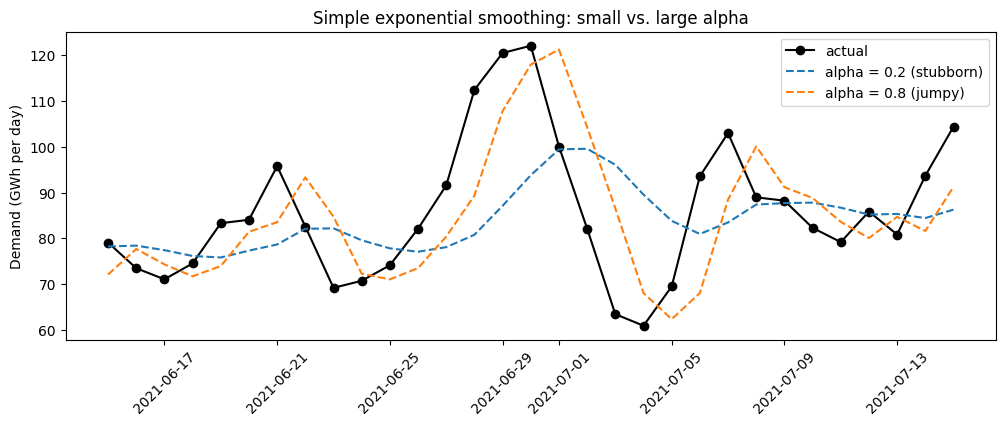

In [7]:
daily['SES_0.2'] = simple_exp_smooth(daily['Demand_GWh'], alpha=0.2)
daily['SES_0.8'] = simple_exp_smooth(daily['Demand_GWh'], alpha=0.8)

window = daily.loc['2021-06-15':'2021-07-15']

plt.figure(figsize=(12, 4))
plt.plot(window.index, window['Demand_GWh'], marker='o', color='black', label='actual')
plt.plot(window.index, window['SES_0.2'], linestyle='--', label='alpha = 0.2 (stubborn)')
plt.plot(window.index, window['SES_0.8'], linestyle='--', label='alpha = 0.8 (jumpy)')
plt.title('Simple exponential smoothing: small vs. large alpha')
plt.ylabel('Demand (GWh per day)')
plt.xticks(rotation=45)
plt.legend()
plt.show()

Alpha = 0.2 is smooth but slow: it barely notices the heat wave. Alpha = 0.8 follows the actual line much more closely.

# 🔴 Grid search: choose alpha on the training years only
Which alpha is best? Don't guess - **try them all** and keep the one with the lowest training MAE. This is called a **grid search**. (Same rule as last week: the 2021 test year stays locked away.)

In [8]:
alphas = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
train_mae = []

for alpha in alphas:
    forecast = simple_exp_smooth(daily['Demand_GWh'], alpha=alpha)
    scores = evaluate(daily.loc['2011':'2020', 'Demand_GWh'], forecast.loc['2011':'2020'])
    train_mae.append(scores['MAE'])
    print('alpha', alpha, '-> train MAE', scores['MAE'])

alpha 0.1 -> train MAE 6.22
alpha 0.2 -> train MAE 5.8
alpha 0.3 -> train MAE 5.65
alpha 0.4 -> train MAE 5.55
alpha 0.5 -> train MAE 5.44
alpha 0.6 -> train MAE 5.32
alpha 0.7 -> train MAE 5.19
alpha 0.8 -> train MAE 5.06
alpha 0.9 -> train MAE 4.94
alpha 1.0 -> train MAE 4.84


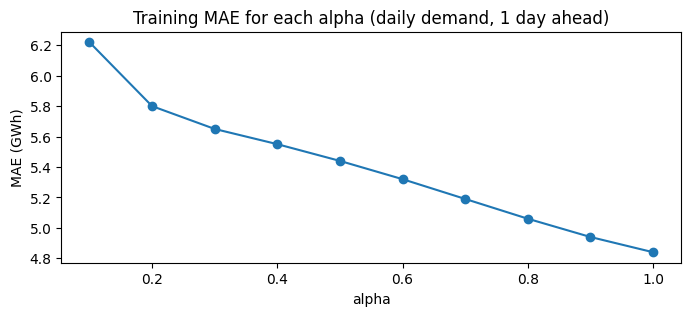

In [9]:
plt.figure(figsize=(8, 3))
plt.plot(alphas, train_mae, marker='o')
plt.title('Training MAE for each alpha (daily demand, 1 day ahead)')
plt.xlabel('alpha')
plt.ylabel('MAE (GWh)')
plt.show()

In [10]:
# np.argmin() gives the POSITION of the smallest value
best_position = np.argmin(train_mae)
best_alpha = alphas[best_position]
print('best alpha:', best_alpha)

best alpha: 1.0


**The best alpha is 1.0 - the naive forecast again!** For tomorrow's demand, the grid search says: trust yesterday completely, don't smooth at all.

That's the same lesson as last week, now confirmed by an optimizer instead of by us: **weather is sticky**, so yesterday is the best single clue. Smoothing would only blur it.

So is exponential smoothing useless here? Not yet - we haven't given it any **seasonality**.

# 🔴 Holt-Winters: level + seasonality
**Holt-Winters** is exponential smoothing that tracks more than one thing at a time:
* the **level** (how high demand is right now), smoothed with **alpha**
* a repeating **seasonal pattern** (here: the 7-day week), smoothed with **gamma**
* (optionally) a **trend**, smoothed with **beta** - we'll skip it; demand only drifts down slowly

We'll use the `statsmodels` library instead of writing it from scratch. `.fit()` runs the grid search for us - it finds the alpha and gamma that minimize the errors on the data we give it. We give it **only the training years**.

In [11]:
train_demand = daily.loc['2011':'2020', 'Demand_GWh']

hw_model = ExponentialSmoothing(train_demand,
                                trend=None,
                                seasonal='add',
                                seasonal_periods=7,
                                initialization_method='estimated')
hw_fit = hw_model.fit()

print('alpha (level):  ', round(hw_fit.params['smoothing_level'], 3))
print('gamma (season): ', round(hw_fit.params['smoothing_seasonal'], 3))

alpha (level):   1.0
gamma (season):  0.0


Look at what the optimizer chose: **alpha = 1** (trust yesterday's level completely) and **gamma = 0** (the weekly pattern never changes).

In plain English: *"Start from yesterday's demand, then add a fixed adjustment for the day of the week."* That's **exactly** the weekday-adjusted naive model we built by hand last week! The optimizer rediscovered our model on its own. 🤯

## Scoring Holt-Winters on 2021 (1 day ahead)
`hw_fit` only knows the training years. To make honest 1-day-ahead forecasts for every day of 2021, we **lock in** the settings it learned (alpha, gamma, and its starting values) and run the same model forward through 2021, one day at a time. No settings are re-learned from 2021.

In [12]:
def holt_winters_one_step(series, fitted, seasonal_periods):
    # Run a Holt-Winters model forward over the whole series using the settings
    # that were learned on the training data (fitted.params). Nothing is re-learned.
    params = fitted.params
    locked = ExponentialSmoothing(series,
                                  trend=None,
                                  seasonal='add',
                                  seasonal_periods=seasonal_periods,
                                  initialization_method='known',
                                  initial_level=params['initial_level'],
                                  initial_seasonal=params['initial_seasons'])
    locked_fit = locked.fit(smoothing_level=params['smoothing_level'],
                            smoothing_seasonal=params['smoothing_seasonal'],
                            optimized=False)
    # fittedvalues = the 1-step-ahead forecast for each period
    return locked_fit.fittedvalues

In [13]:
daily['Holt_Winters'] = holt_winters_one_step(daily['Demand_GWh'], hw_fit, seasonal_periods=7)

# sanity check: on the training years it should match what hw_fit found
check = (daily.loc['2011':'2020', 'Holt_Winters'] - hw_fit.fittedvalues).abs().max()
print('largest difference on the training years:', round(check, 6))

largest difference on the training years: 0.0


In [14]:
test = daily.loc['2021']

models = ['Naive', 'Naive_weekday', 'Holt_Winters', 'SES_0.8', 'SES_0.2']

leaderboard = pd.DataFrame()
for model in models:
    leaderboard[model] = evaluate(test['Demand_GWh'], test[model], naive=test['Naive'])

leaderboard = leaderboard.T.sort_values('MAE')
leaderboard

,n,bias,MAE,RMSE,MAPE (%),skill vs naive (%)
Naive_weekday,365.0,0.02,4.11,5.90,5.23,14.15
Holt_Winters,365.0,0.02,4.11,5.90,5.23,14.14
Naive,365.0,0.02,4.79,6.68,6.15,0.00
SES_0.8,365.0,0.03,5.05,6.99,6.48,-5.53
SES_0.2,365.0,0.06,5.89,8.44,7.55,-23.12


Holt-Winters and our weekday-adjusted naive tie: same MAE, same 14% skill. Two very different roads to the same model. And any alpha below 1 does worse than naive, just like the grid search predicted.

**Takeaway:** a fancier model is not automatically a better model. When an optimizer lands on your simple model, that's a strong sign the simple model was right.

# 🔴 Rule #1 again: change the horizon, change the winner
So far our horizon has been **tomorrow**. But not every business decision is made one day ahead. A utility buys power and schedules maintenance **weeks** ahead, so it cares about **weekly** totals.

Let's add up each week's demand and ask the same questions.

In [15]:
# total demand per week (weeks end on Sunday)
weekly = daily['Demand_GWh'].resample('W-SUN').sum()

# the first and last weeks are partial (2011 starts on a Saturday, 2021 ends on a Friday) - drop them
weekly = weekly.iloc[1:-1]

print(len(weekly), 'weeks from', weekly.index.min().date(), 'to', weekly.index.max().date())
weekly.head()

573 weeks from 2011-01-09 to 2021-12-26


Datetime
2011-01-09    642.485
2011-01-16    659.255
2011-01-23    662.802
2011-01-30    671.285
2011-02-06    656.816
Freq: W-SUN, Name: Demand_GWh, dtype: float64

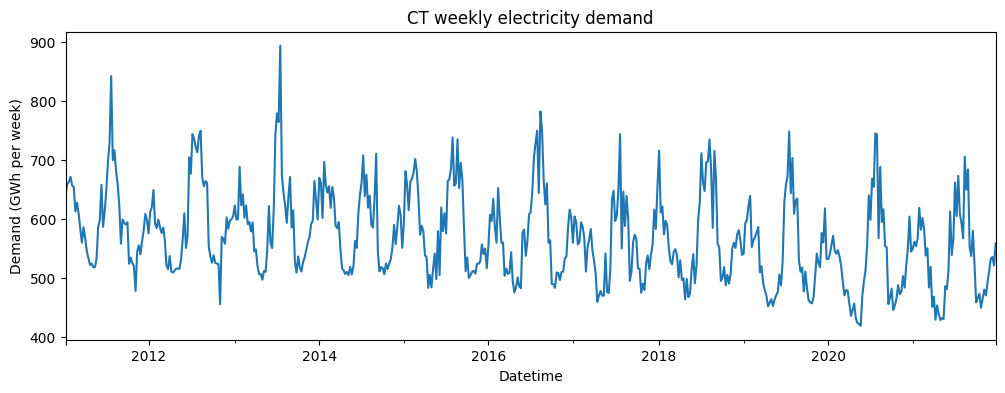

In [16]:
weekly.plot(figsize=(12, 4))
plt.title('CT weekly electricity demand')
plt.ylabel('Demand (GWh per week)')
plt.show()

Adding up 7 days cancels out the weekday pattern - what's left is the **yearly** cycle (summer peaks) plus noise. Same grid search for alpha, training years only:

In [17]:
weekly_naive = weekly.shift(1)

weekly_mae = []
for alpha in alphas:
    forecast = simple_exp_smooth(weekly, alpha=alpha)
    scores = evaluate(weekly.loc['2011':'2020'], forecast.loc['2011':'2020'])
    weekly_mae.append(scores['MAE'])
    print('alpha', alpha, '-> train MAE', scores['MAE'])

best_weekly_alpha = alphas[np.argmin(weekly_mae)]
print('best alpha for weekly totals:', best_weekly_alpha)

alpha 0.1 -> train MAE 54.64
alpha 0.2 -> train MAE 48.43
alpha 0.3 -> train MAE 42.32
alpha 0.4 -> train MAE 38.07
alpha 0.5 -> train MAE 35.27
alpha 0.6 -> train MAE 33.46
alpha 0.7 -> train MAE 32.45
alpha 0.8 -> train MAE 32.01
alpha 0.9 -> train MAE 32.09
alpha 1.0 -> train MAE 32.62
best alpha for weekly totals: 0.8


Now the best alpha is **less than 1** - at the weekly level, a little smoothing beats pure naive. A week's total is noisier relative to its trend, so blending in a bit of the past helps.

Now Holt-Winters with a **yearly** season. With weekly data, one year is 52 periods:

In [18]:
weekly_train = weekly.loc['2011':'2020']

hw_weekly_model = ExponentialSmoothing(weekly_train,
                                       trend=None,
                                       seasonal='add',
                                       seasonal_periods=52,
                                       initialization_method='estimated')
hw_weekly_fit = hw_weekly_model.fit()

print('alpha (level):  ', round(hw_weekly_fit.params['smoothing_level'], 3))
print('gamma (season): ', round(hw_weekly_fit.params['smoothing_seasonal'], 3))

alpha (level):   0.343
gamma (season):  0.071


This time the optimizer picks a **small alpha** (lots of smoothing) and lets the yearly pattern do most of the work. Let's score everything on the 52 weeks of 2021, one week ahead:

In [19]:
weekly_df = pd.DataFrame()
weekly_df['Demand_GWh'] = weekly
weekly_df['Naive'] = weekly_naive
weekly_df['Seasonal_naive (same week last year)'] = weekly.shift(52)
weekly_df['SES best alpha'] = simple_exp_smooth(weekly, alpha=best_weekly_alpha)
weekly_df['Holt_Winters'] = holt_winters_one_step(weekly, hw_weekly_fit, seasonal_periods=52)

weekly_test = weekly_df.loc['2021']

weekly_board = pd.DataFrame()
for model in ['Naive', 'Seasonal_naive (same week last year)', 'SES best alpha', 'Holt_Winters']:
    weekly_board[model] = evaluate(weekly_test['Demand_GWh'], weekly_test[model], naive=weekly_test['Naive'])

weekly_board = weekly_board.T.sort_values('MAE')
weekly_board

,n,bias,MAE,RMSE,MAPE (%),skill vs naive (%)
Holt_Winters,52.0,0.80,27.95,37.11,5.02,21.67
SES best alpha,52.0,0.06,33.05,45.00,5.99,7.38
Seasonal_naive (same week last year),52.0,-8.05,34.90,49.40,6.23,2.17
Naive,52.0,-0.27,35.68,47.43,6.45,0.00


**Now Holt-Winters wins clearly** - its errors are about 22% smaller than naive's. Same family of models, different horizon, very different result.

## One more trick: forecast the whole year at once
Holt-Winters can also forecast **many steps ahead**. Standing on **Dec 31, 2020**, knowing nothing about 2021, let's forecast all 52 weeks of 2021:

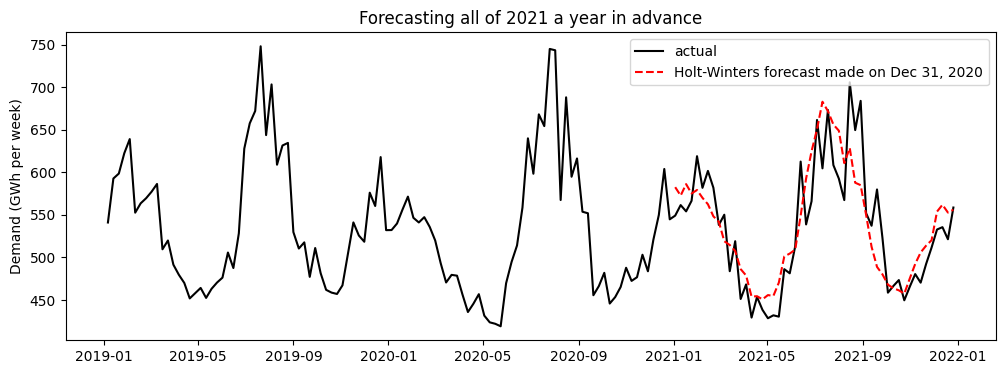

In [20]:
full_year = hw_weekly_fit.forecast(len(weekly_test))

plt.figure(figsize=(12, 4))
plt.plot(weekly.loc['2019':].index, weekly.loc['2019':], color='black', label='actual')
plt.plot(full_year.index, full_year, linestyle='--', color='red', label='Holt-Winters forecast made on Dec 31, 2020')
plt.title('Forecasting all of 2021 a year in advance')
plt.ylabel('Demand (GWh per week)')
plt.legend()
plt.show()

In [21]:
evaluate(weekly_test['Demand_GWh'], full_year)

n           52.00
bias         3.67
MAE         29.11
RMSE        37.51
MAPE (%)     5.27
dtype: float64

A forecast made **a full year ahead** is off by only about 5% per week on average. It gets the shape of the year right - it just can't know *which* weeks will bring the heat waves.

# 🔴 Summary
| Horizon | Best model | What the optimizer told us |
|---|---|---|
| **Tomorrow** (daily) | Weekday-adjusted naive = Holt-Winters (alpha = 1, gamma = 0) | Trust yesterday completely, then adjust for the weekday |
| **Next week** (weekly totals) | Holt-Winters with a yearly season | Smooth a lot (small alpha), lean on the yearly pattern |

The three rules held up all module long:
1. **Know your horizon** - it changed the winner.
2. **Never peek at the future** - every setting was chosen on 2011-2020 only.
3. **Always beat naive** - and report *how much* you beat it by.

# 🦾 On your own
1. **Check the math.** Using `alpha = 0.5`, compute the first three exponential smoothing forecasts for `daily['Demand_GWh']` by hand (or in Excel) and compare with `simple_exp_smooth()`.
2. **Finer grid.** Search alpha in steps of 0.05 between 0.6 and 1.0 for the **weekly** data. Does the best value change?
3. **Add a trend.** Refit the weekly Holt-Winters with `trend='add'` and `damped_trend=True`. Does it beat the version without a trend on the 2021 test year? (You'll need to edit `holt_winters_one_step()` - ask Claude to explain `initial_trend` and `smoothing_trend`, then check its answer against the `statsmodels` documentation.)
4. **Heating oil.** Load `data/ct_heating_oil_weekly_2019_2023.csv` (use `skiprows=1`) and run the alpha grid search on the `CT AVERAGE ($)` column with the last 10 weeks as the test set. Does smoothing beat naive for oil prices?